# <center> xG Predictor Experiment: Model Comparisons <center>

In [ ]:
import torch
from torch.utils.data import DataLoader, random_split, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import ColumnTransformer
import os
import pandas as pd
import glob

In [2]:
# if torch.backends.mps.is_available():
#     device = torch.device('mps')
#     print("MPS device found.")
# else:
#     device = torch.device('cpu')
#     print("MPS device not found.")
device = torch.device('cpu')

class xG_LSTM(nn.Module):
    def __init__(self, input_dim=13, hidden_dim=128, output_dim=1, latent_dim=64, num_layers=3):
        super(xG_LSTM, self).__init__()

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.latent_dim = latent_dim
        self.num_layers = num_layers

        self.lstm_layer = nn.LSTM(self.input_dim, self.hidden_dim, 
                                  self.num_layers, bidirectional=False, batch_first=True)
        
        self.fc_layer = nn.Sequential(
            nn.Linear(self.hidden_dim, self.latent_dim),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(self.latent_dim, self.output_dim)
        )

    def forward(self, x, hidden_states=None):
        if hidden_states is None:
            h_0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
            c_0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
            hidden_states = (h_0, c_0)

        x, hidden_states = self.lstm_layer(x, hidden_states)  # pass hidden_states!
        x = self.fc_layer(x[:, -1, :])

        return x.squeeze(-1)
    
model_spectral_embedding = xG_LSTM(input_dim=13, hidden_dim=256, latent_dim=128)
model_real_units = xG_LSTM(input_dim=16, hidden_dim=256, latent_dim=128)

## <center>Dataset Creation:<center>

In [3]:
DATA_FOLDER = '/Users/marcomaluf/Desktop/Unfinished Projects/paper/training_preprocessed_data'
csvs = os.listdir(DATA_FOLDER)

In [4]:
test = pd.read_csv(f'{DATA_FOLDER}/{csvs[0]}').drop(columns='Unnamed: 0')
test

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball,ball_state,team1_cluster,...,team2_dist_to_ball_state,blue_x_centroid,blue_y_centroid,blue_z_centroid,blue_centroid_dist_to_ball,orange_x_centroid,orange_y_centroid,orange_z_centroid,orange_centroid_dist_to_ball,label
0,0.00,0.00,92.75,0.000000,5202.561923,21.771054,0.0,0.0,-0.079964,-0.477741,...,0.597687,-248.900,-1611.535,27.980,1631.928742,857.545,2905.650,17.010,3030.498622,1.0
1,0.00,0.00,92.75,0.000000,5202.561923,21.771054,0.0,0.0,-0.080267,-0.477661,...,0.598062,-250.440,-1601.105,27.980,1621.867001,849.670,2901.335,17.010,3024.139620,1.0
2,0.00,0.00,92.75,0.000000,5202.561923,21.771054,0.0,0.0,-0.082714,-0.476906,...,0.600977,-176.510,-1479.255,16.545,1491.696463,829.655,2890.560,17.010,3008.222246,1.0
3,0.00,0.00,92.75,0.000000,5202.561923,21.771054,0.0,0.0,-0.083237,-0.476752,...,0.601608,-166.860,-1453.485,16.345,1465.025129,821.470,2886.380,17.010,3001.955865,1.0
4,0.00,0.00,92.75,0.000000,5202.561923,21.771054,0.0,0.0,-0.085680,-0.476032,...,0.604551,-135.345,-1361.655,16.665,1370.478579,821.470,2886.380,17.010,3001.955865,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347,1596.00,4502.19,171.34,9809.846757,1743.938678,34.453758,0.0,0.0,0.076604,-0.508033,...,0.393127,1714.195,2396.580,77.815,2110.997503,2559.505,4601.035,263.535,972.939945,1.0
348,1587.35,4482.97,183.57,9938.981756,1743.289462,35.188024,0.0,0.0,0.075370,-0.508086,...,0.395032,1645.425,2412.700,90.280,2073.184411,2501.890,4624.710,263.535,928.906906,1.0
349,1578.71,4463.77,195.06,10037.630199,1743.007045,35.896841,0.0,0.0,0.074355,-0.508023,...,0.396491,1629.645,2414.080,92.805,2052.871052,2510.720,4629.630,235.560,947.519092,1.0
350,1567.91,4439.80,208.39,10238.948734,1743.132961,36.747527,0.0,0.0,0.069899,-0.508470,...,0.403621,1634.420,2461.190,92.805,1983.098839,2462.790,4646.415,235.560,918.824347,1.0


In [5]:
'''
Combine all the CSVs into one big df, perform standardization and scaling
'''

test_combined = pd.concat([pd.read_csv(f) for f in glob.glob(f"{DATA_FOLDER}/*.csv")], ignore_index=True).drop(columns="Unnamed: 0")
test_combined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 236992 entries, 0 to 236991
Data columns (total 22 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   pos_x                         236992 non-null  float64
 1   pos_y                         236992 non-null  float64
 2   pos_z                         236992 non-null  float64
 3   speed                         236992 non-null  float64
 4   dist_to_goal                  236992 non-null  float64
 5   angle_to_goal                 236992 non-null  float64
 6   players_btwn_ball_and_goal    236992 non-null  float64
 7   players_within_400_of_ball    236992 non-null  float64
 8   ball_state                    236992 non-null  float64
 9   team1_cluster                 236992 non-null  float64
 10  team2_cluster                 236992 non-null  float64
 11  team1_dist_to_ball_state      236992 non-null  float64
 12  team2_dist_to_ball_state      236992 non-nul

In [6]:
class TimeSeriesDataset(Dataset):
    def __init__(self, dataframes, labels):
        """
        Args:
            dataframes (list of pd.DataFrame): List of DataFrames (each is a sequence).
            labels (list of int or float): List of labels (one per DataFrame).
        """
        self.data = [torch.tensor(df, dtype=torch.float32) for df in dataframes]
        self.labels = torch.tensor(labels, dtype=torch.float32)  # Use float32 for regression, long for classification

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

SEQ_LENGTH = 32
NUM_SEQS = int(test_combined.shape[0]/32)

literature_features_indeces = [0,1,2,3,4,5,6,7]
spectral_embedding_features = [8,9,10,11,12]
real_units_features = [13,14,15,16,17,18,19,20]
label=[21]

neg1_to1_scale_cols = ['pos_x', 'pos_y', 'pos_z', 'blue_x_centroid', 'blue_y_centroid', 'blue_z_centroid', 
                       'blue_centroid_dist_to_ball', 'orange_x_centroid', 'orange_y_centroid', 'orange_z_centroid', 
                       'orange_centroid_dist_to_ball']
zero_to1_scale_cols = ['speed', 'dist_to_goal', 'angle_to_goal', 'players_btwn_ball_and_goal', 'players_within_400_of_ball']

preprocessor = ColumnTransformer([
    ('neg1_to1_scale', MinMaxScaler(), neg1_to1_scale_cols),
    ('zero_to1_scale_cols', MinMaxScaler(), zero_to1_scale_cols)
], remainder='passthrough')

transformed_values = preprocessor.fit_transform(test_combined)
test_combined[neg1_to1_scale_cols + zero_to1_scale_cols] = transformed_values[:, :len(neg1_to1_scale_cols) + len(zero_to1_scale_cols)]

In [7]:
labels = []
literature_spectral_features = []
literature_real_units_features = []

cols_spectral = literature_features_indeces + spectral_embedding_features
cols_real = literature_features_indeces + real_units_features

for i in range(NUM_SEQS):
    start, end = SEQ_LENGTH * i, SEQ_LENGTH * (i + 1) 
    
    literature_spectral_features.append(
        test_combined.iloc[start:end, cols_spectral].values 
    )
    literature_real_units_features.append(
        test_combined.iloc[start:end, cols_real].values
    )
    labels.append(test_combined.iloc[start, -1]) 

In [8]:
literature_spectral_dataset = TimeSeriesDataset(literature_spectral_features, labels)
literature_real_units_dataset = TimeSeriesDataset(literature_real_units_features, labels)

In [9]:
len(literature_real_units_dataset)

7406

In [ ]:
## train-test split

### setting set sizes
dataset_size = len(literature_real_units_dataset)
train_pkg_size = 5924 # ~80% of the dataset size
train_set_size = 4443 # 75% of the train package size
val_set_size = train_pkg_size - train_set_size
test_set_size = dataset_size - train_pkg_size # the remaining ~20% of the dataset size

### randomly splitting both the real units set and the spectral units set
real_train_pkg, real_test_set = random_split(literature_real_units_dataset, [train_pkg_size, test_set_size])
real_train_set, real_val_set = random_split(real_train_pkg, [train_set_size, val_set_size])

spectral_train_pkg, spectral_test_set = random_split(literature_spectral_dataset, [train_pkg_size, test_set_size])
spectral_train_set, spectral_val_set = random_split(spectral_train_pkg, [train_set_size, val_set_size])

### setting up the dataloaders for training
real_train_dataloader = DataLoader(real_train_set, batch_size=1024, shuffle=True, drop_last=False)
real_val_dataloader = DataLoader(real_val_set, batch_size=512, shuffle=True, drop_last=False)
real_test_dataloader = DataLoader(real_test_set, batch_size=256, shuffle=False, drop_last=False)

spectral_train_dataloader = DataLoader(spectral_train_set, batch_size=1024, shuffle=True, drop_last=False)
spectral_val_dataloader = DataLoader(spectral_val_set, batch_size=512, shuffle=True, drop_last=False)
spectral_test_dataloader = DataLoader(spectral_test_set, batch_size=256, shuffle=False, drop_last=False)

## <center>Model Training:<center>

In [11]:
def train_one_epoch(model, dataloader, loss_fn, optimizer):
    model.train()
    for batch_x, batch_y in tqdm(dataloader):
        x, y = batch_x.to(device), batch_y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    train_loss = loss.item()
    return train_loss

def evaluate(model, dataloader, loss_fn):
    model.eval()
    all_probs = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for batch_x, batch_y in tqdm(dataloader):
            x, y = batch_x.to(device), batch_y.to(device)
            logits = model(x)                         # raw logits
            probs = torch.sigmoid(logits).squeeze()   # convert to probabilities
            # accumulate loss (weighted by batch size)
            total_loss += loss_fn(logits, y).item() * x.size(0)
            # store results
            all_probs.append(probs.cpu())
            all_labels.append(y.squeeze().cpu())

    # concatenate all batches
    all_probs = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()
    # compute metrics
    avg_loss = total_loss / len(dataloader.dataset)
    roc_auc = roc_auc_score(all_labels, all_probs)

    return avg_loss, roc_auc

In [12]:
LOSS_FN = nn.BCEWithLogitsLoss()
REAL_OPTIMIZER = optim.Adam(model_real_units.parameters(), lr=0.001)
SPECTRAL_OPTIMIZER = optim.Adam(model_spectral_embedding.parameters(), lr=0.001)
EPOCHS = 500
PATIENCE = 10
PATIENCE_COUNTER = 0
MIN_DELTA = 0.00001
BEST_VAL_LOSS = float('inf')

Traning the "real" units model:

In [13]:
real_train_losses = []
real_val_losses = []
real_val_auc_scores = []

for epoch in range(1, EPOCHS+1):
    print(f'Epoch {epoch}:')
    train_loss = train_one_epoch(model_real_units, real_train_dataloader, LOSS_FN, REAL_OPTIMIZER)
    real_train_losses.append(train_loss)

    validation_loss, validation_auc = evaluate(model_real_units, real_val_dataloader, LOSS_FN)
    real_val_losses.append(validation_loss)
    real_val_auc_scores.append(validation_auc)

    print(f"Train Loss: {real_train_losses[-1]:.4f}, Validation Loss: {validation_loss:.4f}, Validation AUC: {validation_auc:.4f}")

    if validation_loss + MIN_DELTA < BEST_VAL_LOSS:
        BEST_VAL_LOSS = validation_loss
        PATIENCE_COUNTER = 0
    else:
        PATIENCE_COUNTER += 1
        if PATIENCE_COUNTER >= PATIENCE:
            print("Early stopping triggered.")
            break

Epoch 1:


100%|██████████| 3/3 [00:00<00:00,  7.34it/s]


Train Loss: 0.6856, Validation Loss: 0.6962, Validation AUC: 0.7325
Epoch 2:


100%|██████████| 3/3 [00:00<00:00,  7.41it/s]


Train Loss: 0.6902, Validation Loss: 0.6912, Validation AUC: 0.7851
Epoch 3:


100%|██████████| 3/3 [00:00<00:00,  7.47it/s]


... (85 outputs left out)

100%|██████████| 3/3 [00:00<00:00,  6.97it/s]


Train Loss: 0.4250, Validation Loss: 0.4654, Validation AUC: 0.8660
Epoch 47:


100%|██████████| 3/3 [00:00<00:00,  6.90it/s]

Train Loss: 0.4870, Validation Loss: 0.4562, Validation AUC: 0.8675
Early stopping triggered.


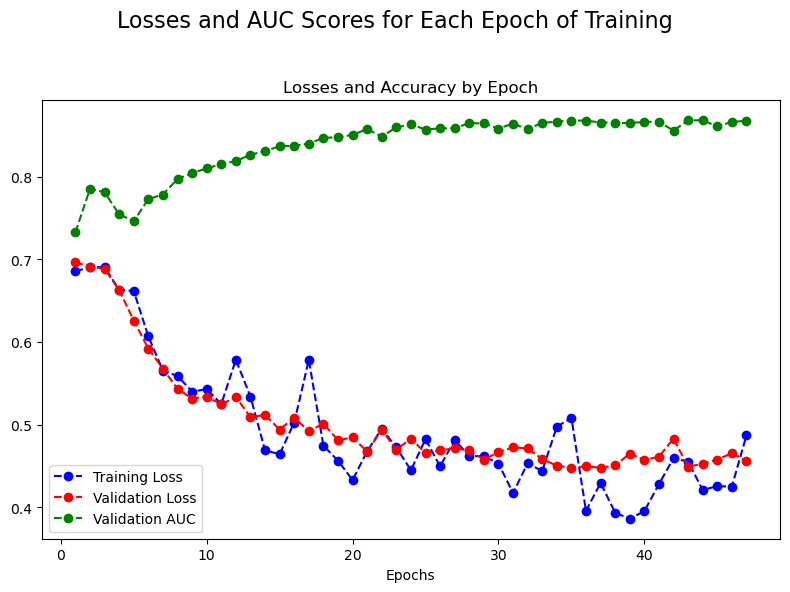

In [14]:
real_training_epochs = [i for i in range(1,epoch+1)]

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(real_training_epochs, real_train_losses, 'o--b', label='Training Loss')
ax.plot(real_training_epochs, real_val_losses, 'o--r', label='Validation Loss')
ax.plot(real_training_epochs, real_val_auc_scores, 'o--g', label='Validation AUC')
ax.set_title('Losses and Accuracy by Epoch')
ax.set_xlabel('Epochs')
ax.legend()

plt.suptitle('Losses and AUC Scores for Each Epoch of Training', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [19]:
real_test_loss, real_test_auc = evaluate(model_real_units, real_test_dataloader, LOSS_FN)
print(f'Test Loss: {real_test_loss} | Test AUC: {real_test_auc}')

100%|██████████| 6/6 [00:00<00:00,  9.04it/s]

Test Loss: 0.47206038047588467 | Test AUC: 0.8562299091991855


Training the Spectral Units model:

In [16]:
# resetting the early stopping hyperparameters
PATIENCE_COUNTER = 0
BEST_VAL_LOSS = float('inf')

spectral_train_losses = []
spectral_val_losses = []
spectral_val_auc_scores = []

for epoch in range(1, EPOCHS+1):
    print(f'Epoch {epoch}:')
    train_loss = train_one_epoch(model_spectral_embedding, spectral_train_dataloader, LOSS_FN, SPECTRAL_OPTIMIZER)
    spectral_train_losses.append(train_loss)

    validation_loss, validation_auc = evaluate(model_spectral_embedding, spectral_val_dataloader, LOSS_FN)
    spectral_val_losses.append(validation_loss)
    spectral_val_auc_scores.append(validation_auc)

    print(f"Train Loss: {spectral_train_losses[-1]:.4f}, Validation Loss: {validation_loss:.4f}, Validation AUC: {validation_auc:.4f}")

    if validation_loss + MIN_DELTA < BEST_VAL_LOSS:
        BEST_VAL_LOSS = validation_loss
        PATIENCE_COUNTER = 0
    else:
        PATIENCE_COUNTER += 1
        if PATIENCE_COUNTER >= PATIENCE:
            print("Early stopping triggered.")
            break

Epoch 1:


100%|██████████| 3/3 [00:00<00:00,  7.34it/s]


Train Loss: 0.6868, Validation Loss: 0.6840, Validation AUC: 0.6975
Epoch 2:


100%|██████████| 3/3 [00:00<00:00,  6.91it/s]


Train Loss: 0.6740, Validation Loss: 0.6553, Validation AUC: 0.6808
Epoch 3:


100%|██████████| 3/3 [00:00<00:00,  7.48it/s]


... (59 outputs left out)

100%|██████████| 3/3 [00:00<00:00,  6.67it/s]


Train Loss: 0.4369, Validation Loss: 0.4718, Validation AUC: 0.8636
Epoch 34:


100%|██████████| 3/3 [00:00<00:00,  6.86it/s]

Train Loss: 0.4508, Validation Loss: 0.4474, Validation AUC: 0.8694
Early stopping triggered.


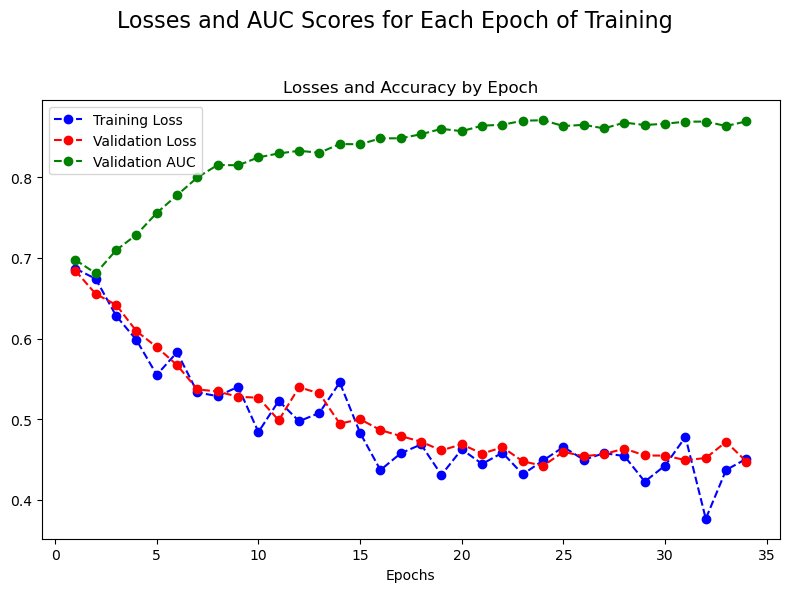

In [17]:
spectral_training_epochs = [i for i in range(1,epoch+1)]

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.plot(spectral_training_epochs, spectral_train_losses, 'o--b', label='Training Loss')
ax.plot(spectral_training_epochs, spectral_val_losses, 'o--r', label='Validation Loss')
ax.plot(spectral_training_epochs, spectral_val_auc_scores, 'o--g', label='Validation AUC')
ax.set_title('Losses and Accuracy by Epoch')
ax.set_xlabel('Epochs')
ax.legend()

plt.suptitle('Losses and AUC Scores for Each Epoch of Training', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [18]:
spectral_test_loss, spectral_test_auc = evaluate(model_spectral_embedding, spectral_test_dataloader, LOSS_FN)
print(f'Test Loss: {spectral_test_loss} | Test AUC: {spectral_test_auc}')

100%|██████████| 6/6 [00:00<00:00,  9.07it/s]

Test Loss: 0.44541953445767907 | Test AUC: 0.8739864032486198


## <center>Feature Importance Experiment<center>

In [ ]:
num_seeds = 20
random_seeds = [9,50,32,37,38,1,42,77,72,3,64,18,67,69,88,23,43,99,56,12]
generators = []
for i in random_seeds:
    generators.append(torch.Generator().manual_seed(i))

In [32]:
def experiment_train_one_epoch(model, dataloader, loss_fn, optimizer):
    model.train()
    for batch_x, batch_y in dataloader:
        x, y = batch_x.to(device), batch_y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    train_loss = loss.item()
    return train_loss

def experiment_evaluate(model, dataloader, loss_fn):
    model.eval()
    all_probs = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            x, y = batch_x.to(device), batch_y.to(device)
            logits = model(x)                         # raw logits
            probs = torch.sigmoid(logits).squeeze()   # convert to probabilities
            # accumulate loss (weighted by batch size)
            total_loss += loss_fn(logits, y).item() * x.size(0)
            # store results
            all_probs.append(probs.cpu())
            all_labels.append(y.squeeze().cpu())

    # concatenate all batches
    all_probs = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()
    # compute metrics
    avg_loss = total_loss / len(dataloader.dataset)
    roc_auc = roc_auc_score(all_labels, all_probs)

    return avg_loss, roc_auc

import shap
import numpy as np

def get_mean_feature_importance(model, dataloader, background_samples=50, device="cpu"):
    model.eval()
    
    all_inputs = torch.cat([X for X, *_ in dataloader]).to(device)
    background = all_inputs[:background_samples]

    class ModelWrapper(torch.nn.Module):
        def __init__(self, model):
            super().__init__()
            self.model = model
        def forward(self, x):
            out = self.model(x)
            return out.unsqueeze(1) if out.dim() == 1 else out

    wrapped_model = ModelWrapper(model)

    explainer = shap.GradientExplainer(wrapped_model, background)
    shap_values = explainer.shap_values(all_inputs)

    if isinstance(shap_values, list):
        shap_values = np.mean([np.abs(sv) for sv in shap_values], axis=0)

    mean_importance = np.abs(shap_values).mean(axis=0, keepdims=True)
    return mean_importance  # shape: (1, n_features)

In [ ]:
final_real_train_losses = []
final_real_val_losses = []
final_real_val_auc_scores = []
final_real_test_loss_scores = []
final_real_test_auc_scores = []
final_real_feature_importances = []

final_spectral_train_losses = []
final_spectral_val_losses = []
final_spectral_val_auc_scores = []
final_spectral_test_loss_scores = []
final_spectral_test_auc_scores = []
final_spectral_feature_importances = []

for i, generator in enumerate(generators):
    print(f'Generator {i+1}')
    ### randomly splitting both the real units set and the spectral units set, setting random seed with generator object
    real_train_pkg, real_test_set = random_split(literature_real_units_dataset, [train_pkg_size, test_set_size], generator=generator)
    real_train_set, real_val_set = random_split(real_train_pkg, [train_set_size, val_set_size])

    spectral_train_pkg, spectral_test_set = random_split(literature_spectral_dataset, [train_pkg_size, test_set_size], generator=generator)
    spectral_train_set, spectral_val_set = random_split(spectral_train_pkg, [train_set_size, val_set_size])

    ### setting up the dataloaders for training
    real_train_dataloader = DataLoader(real_train_set, batch_size=1024, shuffle=True, drop_last=False)
    real_val_dataloader = DataLoader(real_val_set, batch_size=512, shuffle=True, drop_last=False)
    real_test_dataloader = DataLoader(real_test_set, batch_size=256, shuffle=False, drop_last=False)

    spectral_train_dataloader = DataLoader(spectral_train_set, batch_size=1024, shuffle=True, drop_last=False)
    spectral_val_dataloader = DataLoader(spectral_val_set, batch_size=512, shuffle=True, drop_last=False)
    spectral_test_dataloader = DataLoader(spectral_test_set, batch_size=256, shuffle=False, drop_last=False)

    ### define training variables, models
    feature_experiment_model_real_units = xG_LSTM(input_dim=16, hidden_dim=256, latent_dim=128)
    feature_experiment_model_spectral_embedding = xG_LSTM(input_dim=13, hidden_dim=256, latent_dim=128)

    LOSS_FN = nn.BCEWithLogitsLoss()
    REAL_OPTIMIZER = optim.Adam(feature_experiment_model_real_units.parameters(), lr=0.001)
    SPECTRAL_OPTIMIZER = optim.Adam(feature_experiment_model_spectral_embedding.parameters(), lr=0.001)
    EPOCHS = 500
    MIN_DELTA = 0.00001
    PATIENCE = 10

    ### start the training loop:
    #### training the real units model first 
    PATIENCE_COUNTER = 0
    BEST_VAL_LOSS = float('inf')

    for epoch in range(1, EPOCHS+1):
        print('Real Units Model')
        print(f"Epoch {i:<10}", end='\r', flush=True)
        train_loss = experiment_train_one_epoch(feature_experiment_model_real_units, real_train_dataloader, LOSS_FN, REAL_OPTIMIZER)

        validation_loss, validation_auc = experiment_evaluate(feature_experiment_model_real_units, real_val_dataloader, LOSS_FN)

        if validation_loss + MIN_DELTA < BEST_VAL_LOSS:
            BEST_VAL_LOSS = validation_loss
            PATIENCE_COUNTER = 0
        else:
            PATIENCE_COUNTER += 1
            if PATIENCE_COUNTER >= PATIENCE:
                print("Early stopping triggered.")
                break
    
    real_test_loss, real_test_auc = evaluate(feature_experiment_model_real_units, real_test_dataloader, LOSS_FN)
    real_feature_importances = get_mean_feature_importance(feature_experiment_model_real_units, real_test_dataloader)

    final_real_train_losses.append(train_loss)
    final_real_val_losses.append(validation_loss)
    final_real_val_auc_scores.append(validation_auc)
    final_real_test_loss_scores.append(real_test_loss)
    final_real_test_auc_scores.append(real_test_auc)
    final_real_feature_importances.append(real_feature_importances)
    
    #### training the spectral units model
    PATIENCE_COUNTER = 0
    BEST_VAL_LOSS = float('inf')

    for epoch in range(1, EPOCHS+1):
        print('Spectral Embedding Model')
        print(f"Epoch {i:<10}", end='\r', flush=True)
        train_loss = experiment_train_one_epoch(feature_experiment_model_spectral_embedding, spectral_train_dataloader, LOSS_FN, SPECTRAL_OPTIMIZER)

        validation_loss, validation_auc = experiment_evaluate(feature_experiment_model_spectral_embedding, spectral_val_dataloader, LOSS_FN)

        if validation_loss + MIN_DELTA < BEST_VAL_LOSS:
            BEST_VAL_LOSS = validation_loss
            PATIENCE_COUNTER = 0
        else:
            PATIENCE_COUNTER += 1
            if PATIENCE_COUNTER >= PATIENCE:
                print("Early stopping triggered.")
                break
    
    spectral_test_loss, spectral_test_auc = evaluate(feature_experiment_model_spectral_embedding, spectral_test_dataloader, LOSS_FN)
    spectral_feature_importances = get_mean_feature_importance(feature_experiment_model_spectral_embedding, spectral_test_dataloader)

    final_spectral_train_losses.append(train_loss)
    final_spectral_val_losses.append(validation_loss)
    final_spectral_val_auc_scores.append(validation_auc)
    final_spectral_test_loss_scores.append(spectral_test_loss)
    final_spectral_test_auc_scores.append(spectral_test_auc)
    final_spectral_feature_importances.append(spectral_feature_importances)

In [33]:
from IPython.display import display

final_real_train_losses = []
final_real_val_losses = []
final_real_val_auc_scores = []
final_real_test_loss_scores = []
final_real_test_auc_scores = []
final_real_feature_importances = []

final_spectral_train_losses = []
final_spectral_val_losses = []
final_spectral_val_auc_scores = []
final_spectral_test_loss_scores = []
final_spectral_test_auc_scores = []
final_spectral_feature_importances = []

for i, generator in enumerate(generators):
    gen_out = display(f'Generator {i+1}', display_id=True)
    real_out = display('', display_id=True)
    epoch_real_out = display('', display_id=True)
    spec_out = display('', display_id=True)
    epoch_spec_out = display('', display_id=True)

    gen_out.update(f'Generator {i+1}')

    ### randomly splitting both the real units set and the spectral units set, setting random seed with generator object
    real_train_pkg, real_test_set = random_split(literature_real_units_dataset, [train_pkg_size, test_set_size], generator=generator)
    real_train_set, real_val_set = random_split(real_train_pkg, [train_set_size, val_set_size])

    spectral_train_pkg, spectral_test_set = random_split(literature_spectral_dataset, [train_pkg_size, test_set_size], generator=generator)
    spectral_train_set, spectral_val_set = random_split(spectral_train_pkg, [train_set_size, val_set_size])

    ### setting up the dataloaders for training
    real_train_dataloader = DataLoader(real_train_set, batch_size=1024, shuffle=True, drop_last=False)
    real_val_dataloader = DataLoader(real_val_set, batch_size=512, shuffle=True, drop_last=False)
    real_test_dataloader = DataLoader(real_test_set, batch_size=256, shuffle=False, drop_last=False)

    spectral_train_dataloader = DataLoader(spectral_train_set, batch_size=1024, shuffle=True, drop_last=False)
    spectral_val_dataloader = DataLoader(spectral_val_set, batch_size=512, shuffle=True, drop_last=False)
    spectral_test_dataloader = DataLoader(spectral_test_set, batch_size=256, shuffle=False, drop_last=False)

    ### define training variables, models
    feature_experiment_model_real_units = xG_LSTM(input_dim=16, hidden_dim=256, latent_dim=128)
    feature_experiment_model_spectral_embedding = xG_LSTM(input_dim=13, hidden_dim=256, latent_dim=128)

    LOSS_FN = nn.BCEWithLogitsLoss()
    REAL_OPTIMIZER = optim.Adam(feature_experiment_model_real_units.parameters(), lr=0.001)
    SPECTRAL_OPTIMIZER = optim.Adam(feature_experiment_model_spectral_embedding.parameters(), lr=0.001)
    EPOCHS = 500
    MIN_DELTA = 0.00001
    PATIENCE = 10

    ### start the training loop:
    #### training the real units model first
    PATIENCE_COUNTER = 0
    BEST_VAL_LOSS = float('inf')

    real_out.update('Real Units Model')

    for epoch in range(1, EPOCHS+1):
        epoch_real_out.update(f'  Epoch {epoch}/{EPOCHS}  |  (training...)')
        train_loss = experiment_train_one_epoch(feature_experiment_model_real_units, real_train_dataloader, LOSS_FN, REAL_OPTIMIZER)

        validation_loss, validation_auc = experiment_evaluate(feature_experiment_model_real_units, real_val_dataloader, LOSS_FN)
        epoch_real_out.update(f'  Epoch {epoch}/{EPOCHS}  |  train_loss: {train_loss:.4f}  |  val_loss: {validation_loss:.4f}  |  val_auc: {validation_auc:.4f}')

        if validation_loss + MIN_DELTA < BEST_VAL_LOSS:
            BEST_VAL_LOSS = validation_loss
            PATIENCE_COUNTER = 0
        else:
            PATIENCE_COUNTER += 1
            if PATIENCE_COUNTER >= PATIENCE:
                epoch_real_out.update(f'  Early stopping at epoch {epoch}.')
                break

    real_test_loss, real_test_auc = evaluate(feature_experiment_model_real_units, real_test_dataloader, LOSS_FN)
    real_feature_importances = get_mean_feature_importance(feature_experiment_model_real_units, real_test_dataloader)

    final_real_train_losses.append(train_loss)
    final_real_val_losses.append(validation_loss)
    final_real_val_auc_scores.append(validation_auc)
    final_real_test_loss_scores.append(real_test_loss)
    final_real_test_auc_scores.append(real_test_auc)
    final_real_feature_importances.append(real_feature_importances)

    #### training the spectral units model
    PATIENCE_COUNTER = 0
    BEST_VAL_LOSS = float('inf')

    spec_out.update('Spectral Embedding Model')

    for epoch in range(1, EPOCHS+1):
        epoch_spec_out.update(f'  Epoch {epoch}/{EPOCHS}  |  (training...)')
        train_loss = experiment_train_one_epoch(feature_experiment_model_spectral_embedding, spectral_train_dataloader, LOSS_FN, SPECTRAL_OPTIMIZER)

        validation_loss, validation_auc = experiment_evaluate(feature_experiment_model_spectral_embedding, spectral_val_dataloader, LOSS_FN)
        epoch_spec_out.update(f'  Epoch {epoch}/{EPOCHS}  |  train_loss: {train_loss:.4f}  |  val_loss: {validation_loss:.4f}  |  val_auc: {validation_auc:.4f}')

        if validation_loss + MIN_DELTA < BEST_VAL_LOSS:
            BEST_VAL_LOSS = validation_loss
            PATIENCE_COUNTER = 0
        else:
            PATIENCE_COUNTER += 1
            if PATIENCE_COUNTER >= PATIENCE:
                epoch_spec_out.update(f'  Early stopping at epoch {epoch}.')
                break

    spectral_test_loss, spectral_test_auc = evaluate(feature_experiment_model_spectral_embedding, spectral_test_dataloader, LOSS_FN)
    spectral_feature_importances = get_mean_feature_importance(feature_experiment_model_spectral_embedding, spectral_test_dataloader)

    final_spectral_train_losses.append(train_loss)
    final_spectral_val_losses.append(validation_loss)
    final_spectral_val_auc_scores.append(validation_auc)
    final_spectral_test_loss_scores.append(spectral_test_loss)
    final_spectral_test_auc_scores.append(spectral_test_auc)
    final_spectral_feature_importances.append(spectral_feature_importances)

'Generator 1'

'Real Units Model'

'  Early stopping at epoch 53.'

'Spectral Embedding Model'

'  Early stopping at epoch 59.'

100%|██████████| 6/6 [00:00<00:00, 10.44it/s]


... (110 outputs left out)

'  Early stopping at epoch 37.'

'Spectral Embedding Model'

'  Early stopping at epoch 66.'

100%|██████████| 6/6 [00:00<00:00,  8.32it/s]


### Manually logging training/testing results in case of something awry (e.g. loss/reset of kernel)

(to be used into a separate file for analysis)

final_real_train_losses = [0.39990752935409546,
 0.49353620409965515,
 0.4068042039871216,
 0.4015471339225769,
 0.4878668785095215,
 0.4474802613258362,
 0.42905810475349426,
 0.4889605939388275,
 0.4231249988079071,
 0.5138744711875916,
 0.4253491759300232,
 0.4795553386211395,
 0.41867223381996155,
 0.42937883734703064,
 0.44224604964256287,
 0.4477214515209198,
 0.4339037239551544,
 0.4576416015625,
 0.4732964038848877,
 0.40103286504745483]

final_real_val_losses = [0.452987141459476,
 0.5021475603015418,
 0.4529168948903428,
 0.4603824837637624,
 0.45242117060591125,
 0.45376318262526505,
 0.48587935237285657,
 0.4618482068935654,
 0.4391970842332151,
 0.44589137829774783,
 0.4680578778073403,
 0.45799422988530997,
 0.446782488504187,
 0.44420772746637976,
 0.4592978406765427,
 0.46616121233113306,
 0.465965396503916,
 0.47279784773588984,
 0.4654615469915814,
 0.4666804651566891]

final_real_val_auc_scores = [0.8637463947259992,
 0.8528995496737432,
 0.8719738848646588,
 0.8774379529980233,
 0.8697740889353047,
 0.864115334784316,
 0.8528067681298376,
 0.8708672517246796,
 0.8771925978699695,
 0.8827724965187549,
 0.86116372341862,
 0.8666955585998186,
 0.8679356666362057,
 0.8753189243086308,
 0.8684109624057406,
 0.8608274225618754,
 0.8611396228628405,
 0.8527317352352022,
 0.8642308395829523,
 0.8581732349010932]

final_real_test_loss_scores = [0.4752770452364254,
 0.4702821013174559,
 0.45274145907236013,
 0.50092881853603,
 0.4559619396563001,
 0.43480373470567657,
 0.47577344023907875,
 0.46637607763009836,
 0.443354016614829,
 0.4675243890237229,
 0.47573389641829994,
 0.4891573740081427,
 0.4595881525562842,
 0.4443688609017695,
 0.44373149395632516,
 0.46250120308074233,
 0.483174156080856,
 0.4384048654724229,
 0.4643185579101084,
 0.47670566866755004]

final_real_test_auc_scores = [0.8523126519684179,
 0.8673688160428139,
 0.8736248381222362,
 0.8539983338368442,
 0.8663320565315018,
 0.8819983198188327,
 0.8616161801378905,
 0.8651398933450215,
 0.8691439159524266,
 0.8731381350744747,
 0.8520750988142292,
 0.8420766453124401,
 0.8635397767655675,
 0.8704141149023039,
 0.8831502134104364,
 0.8620199146514936,
 0.8510828219675751,
 0.8737746150094706,
 0.8609080387359538,
 0.851001403708359]

final_spectral_train_losses = [0.40689557790756226,
 0.39625272154808044,
 0.45266473293304443,
 0.40264469385147095,
 0.48558738827705383,
 0.4525580406188965,
 0.3723377585411072,
 0.46629655361175537,
 0.4154679477214813,
 0.46419715881347656,
 0.3993241786956787,
 0.42200493812561035,
 0.3521452248096466,
 0.4907016456127167,
 0.38353270292282104,
 0.35074949264526367,
 0.3659571409225464,
 0.4312259256839752,
 0.48637428879737854,
 0.3791826665401459]

final_spectral_val_losses = [0.4550228477289031,
 0.4367051624229516,
 0.47479845449620206,
 0.46282922718510444,
 0.4571500713361589,
 0.43708194260014466,
 0.44383813826157226,
 0.4250331785854337,
 0.4671936656759044,
 0.42150862839960873,
 0.43146827263577736,
 0.4424081792870057,
 0.4354245409741746,
 0.4536325799943948,
 0.4148149312065712,
 0.47453263055867717,
 0.4551634372166087,
 0.4622749042905399,
 0.4636856033180631,
 0.4437802477835965]

final_spectral_val_auc_scores = [0.8700529725943438,
 0.8780537772087068,
 0.8695401731345247,
 0.8656959228760797,
 0.875910716892977,
 0.8757708767694502,
 0.8876010461245839,
 0.8870259437319986,
 0.8638903005796525,
 0.8834282134895632,
 0.8916398279893059,
 0.8752504406660901,
 0.8850620100620101,
 0.8656904453249101,
 0.8896202336967068,
 0.8668288367978769,
 0.8692740256312503,
 0.8718333515901706,
 0.8648917248840235,
 0.8791733506200512]

final_spectral_test_loss_scores = [0.46136407166035714,
 0.430916177840368,
 0.519557649709596,
 0.4485359555877011,
 0.48497812954681285,
 0.438412366286624,
 0.4766799896834833,
 0.46263774264196633,
 0.4389338111266112,
 0.41098208120155594,
 0.473519100190496,
 0.4243170693013993,
 0.4453585279776178,
 0.42594925723416927,
 0.4637250762317184,
 0.4603998178412557,
 0.46257490056407274,
 0.4681986912220274,
 0.463363752191366,
 0.49545242308605053]

final_spectral_test_auc_scores = [0.8629568912619403,
 0.8833904859185758,
 0.8499460342998295,
 0.8697920948919914,
 0.85073612393557,
 0.8786889732175437,
 0.8698199183435404,
 0.8596920501725045,
 0.8817006355467893,
 0.8912711263949932,
 0.8648228441291115,
 0.8867456871002395,
 0.8757044072682879,
 0.8837534194473295,
 0.8635428212483816,
 0.8748796022992077,
 0.8675217886392502,
 0.8710674814338343,
 0.8687312584959961,
 0.8620431281212583]

For the feature importances, I need to transform and aggregate the data so that the final array is length 20 (for each random seed), and each of the 20 entries is an array of shape `(1, n_features)` that is the mean feature importance of each feature for that training iteration:

In [72]:
def aggregate_feature_importances(feature_importances_array):
    final_array = []
    for arr in feature_importances_array:
        sv = np.abs(arr)                      # (1, n_samples, n_features, 1)
        mean_imp = sv.mean(axis=(0, 1, 3))    # → (n_features,)
        final_array.append(mean_imp.reshape(1, -1))  # → (1, 16)
    return final_array

In [73]:
final_real_feature_importances_aggregated = aggregate_feature_importances(final_real_feature_importances)
final_real_feature_importances_aggregated

[array([[5.70737792e-03, 2.65874443e-02, 1.09065633e-01, 9.37693875e-03,
         1.90630186e-01, 1.18920982e-01, 2.09267883e-03, 1.25674507e-02,
         2.01196693e-04, 2.11977507e-04, 1.34552525e-04, 8.25474920e-04,
         4.42982530e-04, 4.03495400e-04, 1.62554120e-04, 5.46540148e-04]]),
 array([[1.45722530e-02, 3.48903364e-02, 1.00627315e-01, 7.00837203e-03,
         1.84494779e-01, 9.83942572e-02, 2.56203301e-03, 7.80146823e-03,
         8.50533957e-05, 3.96576052e-04, 9.49803910e-05, 1.65527506e-03,
         1.11722972e-04, 2.78493677e-04, 3.19003047e-05, 2.21239622e-03]]),
 array([[1.70668918e-02, 5.39964313e-02, 1.58722431e-01, 1.88936728e-02,
         4.20330486e-01, 1.91892822e-01, 1.02209642e-02, 2.33312368e-02,
         7.36394335e-04, 7.02493638e-04, 1.59852701e-04, 1.64748531e-03,
         2.74789021e-04, 6.31044373e-04, 8.49081757e-05, 2.24468956e-03]]),
 array([[1.03862079e-02, 2.22618018e-02, 1.19818084e-01, 8.36325992e-03,
         1.93879541e-01, 9.14992976e-02, 2

final_real_feature_importances_aggregated = [array([[5.70737792e-03, 2.65874443e-02, 1.09065633e-01, 9.37693875e-03,
         1.90630186e-01, 1.18920982e-01, 2.09267883e-03, 1.25674507e-02,
         2.01196693e-04, 2.11977507e-04, 1.34552525e-04, 8.25474920e-04,
         4.42982530e-04, 4.03495400e-04, 1.62554120e-04, 5.46540148e-04]]),
 array([[1.45722530e-02, 3.48903364e-02, 1.00627315e-01, 7.00837203e-03,
         1.84494779e-01, 9.83942572e-02, 2.56203301e-03, 7.80146823e-03,
         8.50533957e-05, 3.96576052e-04, 9.49803910e-05, 1.65527506e-03,
         1.11722972e-04, 2.78493677e-04, 3.19003047e-05, 2.21239622e-03]]),
 array([[1.70668918e-02, 5.39964313e-02, 1.58722431e-01, 1.88936728e-02,
         4.20330486e-01, 1.91892822e-01, 1.02209642e-02, 2.33312368e-02,
         7.36394335e-04, 7.02493638e-04, 1.59852701e-04, 1.64748531e-03,
         2.74789021e-04, 6.31044373e-04, 8.49081757e-05, 2.24468956e-03]]),
 array([[1.03862079e-02, 2.22618018e-02, 1.19818084e-01, 8.36325992e-03,
         1.93879541e-01, 9.14992976e-02, 2.53770745e-03, 1.64485289e-02,
         1.63692798e-04, 1.71072927e-04, 2.60417924e-05, 1.82025140e-03,
         2.94076473e-04, 1.00607195e-04, 3.78479130e-04, 3.79044947e-04]]),
 array([[7.76620375e-03, 1.71813601e-02, 1.07094380e-01, 1.08813997e-02,
         2.66614854e-01, 1.42397754e-01, 3.32839851e-03, 1.33142614e-02,
         3.11597832e-04, 2.12613906e-04, 1.16167993e-04, 8.99262345e-04,
         1.27044563e-04, 5.99028500e-05, 1.11472560e-04, 4.69238915e-04]]),
 array([[1.81554111e-02, 1.76277417e-02, 1.92559444e-01, 2.38025643e-02,
         3.52909354e-01, 1.80041224e-01, 4.99381621e-03, 1.77226363e-02,
         6.58979525e-05, 7.18413573e-04, 8.01780158e-05, 1.51302090e-03,
         3.95621452e-04, 6.47756349e-04, 3.38086490e-04, 5.41843154e-04]]),
 array([[7.84553763e-03, 2.12200154e-02, 9.83654602e-02, 1.53411606e-02,
         2.31405091e-01, 9.15769991e-02, 3.81900645e-03, 2.53737869e-02,
         2.33195934e-04, 4.50256839e-04, 3.36362373e-05, 2.25216285e-03,
         2.23164017e-04, 6.40100826e-04, 2.23819516e-05, 2.19041993e-04]]),
 array([[1.67962273e-02, 3.44356095e-02, 1.92433678e-01, 1.09167270e-02,
         2.60952075e-01, 1.27765895e-01, 6.16821785e-03, 3.03522189e-02,
         2.59477188e-04, 4.72632187e-04, 1.54125882e-04, 1.46486647e-03,
         1.27025625e-04, 2.46746137e-04, 1.00701203e-04, 9.05604502e-04]]),
 array([[2.09960776e-02, 1.80608696e-02, 2.06399702e-01, 1.50924993e-02,
         3.50462781e-01, 1.81916778e-01, 4.57665612e-03, 1.97579558e-02,
         4.44951180e-04, 2.09346477e-03, 2.70692172e-04, 9.14474727e-03,
         1.10954712e-04, 7.00928697e-04, 2.35814484e-04, 7.32348659e-04]]),
 array([[2.50217119e-02, 5.86201139e-02, 2.08257019e-01, 1.54062814e-02,
         4.09908449e-01, 1.87784401e-01, 4.38430172e-03, 2.31354774e-02,
         3.01140377e-04, 4.33580932e-04, 1.35372568e-04, 4.34845862e-03,
         2.40875918e-04, 4.41441227e-04, 1.61609619e-04, 1.77419239e-03]]),
 array([[6.32412535e-03, 1.40851647e-02, 9.02221934e-02, 9.03458133e-03,
         1.79495741e-01, 9.74231268e-02, 3.85838031e-03, 1.29309408e-02,
         2.48641896e-04, 5.88475714e-05, 5.39740876e-05, 1.57018948e-03,
         5.44725343e-04, 2.01989065e-03, 1.45168042e-03, 5.65423613e-03]]),
 array([[0.01004476, 0.02248111, 0.14274716, 0.01189308, 0.23336223,
         0.13504561, 0.002304  , 0.00736984, 0.00026568, 0.00036291,
         0.00044716, 0.00199832, 0.00159687, 0.00166607, 0.00227797,
         0.00609418]]),
 array([[9.09093969e-03, 1.70376501e-02, 1.79166693e-01, 1.61968452e-02,
         2.49457685e-01, 1.43803016e-01, 3.62592635e-03, 2.73626983e-02,
         1.28567945e-04, 6.79879414e-04, 1.13406050e-04, 2.52661614e-03,
         3.60465643e-04, 3.15701916e-04, 4.91992601e-05, 4.39123963e-04]]),
 array([[1.60841046e-02, 1.97908994e-02, 1.66127764e-01, 2.24328460e-02,
         2.68325418e-01, 1.49688808e-01, 4.61009953e-03, 1.73785531e-02,
         2.57396440e-04, 5.28953606e-04, 3.30398270e-04, 1.72910862e-02,
         8.58424106e-05, 7.20153502e-04, 8.27362881e-04, 7.05597398e-04]]),
 array([[9.31235372e-03, 3.44953101e-02, 2.15637819e-01, 2.32398436e-02,
         3.48765239e-01, 1.77764622e-01, 2.78829996e-03, 1.51565395e-02,
         3.45881935e-04, 5.35054505e-04, 6.54031629e-05, 2.01488353e-03,
         3.83095598e-04, 2.84252057e-04, 6.20267325e-05, 1.12385105e-04]]),
 array([[1.22411094e-02, 1.55922331e-02, 2.09899195e-01, 8.65051950e-03,
         3.53667765e-01, 1.67994737e-01, 3.40058444e-03, 1.97490021e-02,
         4.87091012e-04, 2.03064872e-04, 9.85303776e-05, 3.43074907e-03,
         2.97337345e-04, 1.94393687e-04, 1.89072986e-05, 1.92024346e-04]]),
 array([[1.69376154e-02, 9.40418898e-03, 1.02100455e-01, 8.52405414e-03,
         1.47713939e-01, 9.13028984e-02, 4.63412488e-03, 2.51523339e-02,
         6.26492649e-05, 2.14688433e-04, 1.12704956e-04, 1.09791185e-03,
         4.78278931e-04, 2.45198079e-04, 1.31930215e-04, 2.91262411e-04]]),
 array([[1.33469822e-02, 1.34198473e-02, 1.69854105e-01, 1.59696716e-02,
         2.57619968e-01, 1.21115413e-01, 1.12336477e-03, 2.18710454e-02,
         1.50294247e-03, 1.79820977e-03, 9.03509323e-04, 1.37609576e-02,
         5.43832473e-04, 3.06077220e-04, 1.13366343e-04, 4.61612407e-04]]),
 array([[1.83290877e-02, 1.66565502e-02, 1.33560698e-01, 1.51359134e-02,
         2.27452540e-01, 1.14559895e-01, 3.94755224e-03, 1.26531600e-02,
         1.08326664e-04, 5.07147284e-04, 7.94377576e-05, 1.90771286e-03,
         1.01695033e-04, 2.43652965e-04, 9.73415993e-05, 3.14109669e-04]]),
 array([[2.99522528e-03, 4.49978863e-02, 1.53263192e-01, 1.87009073e-02,
         2.66610703e-01, 1.50635232e-01, 5.86844140e-03, 2.06438746e-02,
         1.45452320e-04, 8.18993748e-04, 4.55787688e-05, 9.55095268e-04,
         2.15482537e-03, 6.21133920e-04, 2.11623807e-03, 8.47985669e-03]])]

In [74]:
final_spectral_feature_importances_aggregated = aggregate_feature_importances(final_spectral_feature_importances)
final_spectral_feature_importances_aggregated

[array([[0.0125547 , 0.02264556, 0.12257207, 0.01620898, 0.23341123,
         0.10219311, 0.00531894, 0.01449013, 0.00993358, 0.0180224 ,
         0.02506185, 0.03149662, 0.02232201]]),
 array([[0.02116315, 0.06291722, 0.19011649, 0.02760581, 0.33151947,
         0.16850383, 0.00299648, 0.01819252, 0.01784426, 0.04383782,
         0.03300059, 0.02748201, 0.04122407]]),
 array([[0.01102635, 0.02887606, 0.13966964, 0.01416259, 0.22891489,
         0.10763407, 0.00294653, 0.03758155, 0.01306359, 0.03016472,
         0.02377011, 0.01964987, 0.02410472]]),
 array([[0.0295168 , 0.04118627, 0.12789033, 0.0098076 , 0.29881581,
         0.14369252, 0.00854385, 0.02712274, 0.01428144, 0.05255547,
         0.05361125, 0.03141196, 0.02907532]]),
 array([[0.00686672, 0.0133767 , 0.09602028, 0.01221127, 0.14259419,
         0.08313792, 0.00339422, 0.01977266, 0.00599597, 0.01660295,
         0.01765556, 0.01180521, 0.01075942]]),
 array([[0.01866379, 0.02871351, 0.10207314, 0.01341718, 0.21462762,
 

final_spectral_feature_importances_aggregated = [array([[0.0125547 , 0.02264556, 0.12257207, 0.01620898, 0.23341123,
         0.10219311, 0.00531894, 0.01449013, 0.00993358, 0.0180224 ,
         0.02506185, 0.03149662, 0.02232201]]),
 array([[0.02116315, 0.06291722, 0.19011649, 0.02760581, 0.33151947,
         0.16850383, 0.00299648, 0.01819252, 0.01784426, 0.04383782,
         0.03300059, 0.02748201, 0.04122407]]),
 array([[0.01102635, 0.02887606, 0.13966964, 0.01416259, 0.22891489,
         0.10763407, 0.00294653, 0.03758155, 0.01306359, 0.03016472,
         0.02377011, 0.01964987, 0.02410472]]),
 array([[0.0295168 , 0.04118627, 0.12789033, 0.0098076 , 0.29881581,
         0.14369252, 0.00854385, 0.02712274, 0.01428144, 0.05255547,
         0.05361125, 0.03141196, 0.02907532]]),
 array([[0.00686672, 0.0133767 , 0.09602028, 0.01221127, 0.14259419,
         0.08313792, 0.00339422, 0.01977266, 0.00599597, 0.01660295,
         0.01765556, 0.01180521, 0.01075942]]),
 array([[0.01866379, 0.02871351, 0.10207314, 0.01341718, 0.21462762,
         0.12368317, 0.00801225, 0.01364858, 0.00643435, 0.02246489,
         0.02355176, 0.02924148, 0.02300326]]),
 array([[0.0189647 , 0.02495112, 0.16227035, 0.01806557, 0.28970984,
         0.18128808, 0.00834843, 0.02057769, 0.00911942, 0.03080415,
         0.03835787, 0.02845009, 0.03821323]]),
 array([[0.01307596, 0.04020226, 0.1715117 , 0.00850098, 0.26902954,
         0.1443052 , 0.00313903, 0.02779638, 0.00611508, 0.02023748,
         0.01429098, 0.02553311, 0.02762702]]),
 array([[0.04987432, 0.06667119, 0.14234225, 0.02896871, 0.51036588,
         0.26683664, 0.00791072, 0.02630713, 0.0216302 , 0.02814384,
         0.04510656, 0.05776372, 0.05220093]]),
 array([[0.01061022, 0.03949511, 0.12507119, 0.01067617, 0.22263767,
         0.12582851, 0.00282546, 0.01459973, 0.01227815, 0.0338618 ,
         0.02744478, 0.0235245 , 0.0314359 ]]),
 array([[0.0144968 , 0.0481766 , 0.15249285, 0.01394631, 0.30265682,
         0.11087976, 0.00376444, 0.03318108, 0.01104078, 0.04154894,
         0.05290868, 0.0232629 , 0.02953017]]),
 array([[0.02590481, 0.02302611, 0.14209169, 0.01655753, 0.31539012,
         0.15554891, 0.00353438, 0.02153158, 0.00985778, 0.03400867,
         0.02243116, 0.03802694, 0.03193608]]),
 array([[0.01570119, 0.04400915, 0.20460344, 0.01879918, 0.33078535,
         0.17496941, 0.00509987, 0.02337952, 0.01688319, 0.05278981,
         0.04641182, 0.03701376, 0.05002012]]),
 array([[0.02407149, 0.03419967, 0.15961615, 0.0184799 , 0.42096385,
         0.21230026, 0.00313194, 0.01627043, 0.00979719, 0.04007275,
         0.05150449, 0.04087908, 0.03184502]]),
 array([[0.0104358 , 0.02044986, 0.15999843, 0.0084546 , 0.23401929,
         0.17900782, 0.00215786, 0.01987991, 0.00833235, 0.04787983,
         0.05700686, 0.02719756, 0.0314174 ]]),
 array([[0.00822466, 0.04058121, 0.177525  , 0.01887777, 0.34179459,
         0.2088032 , 0.00670371, 0.03147691, 0.01029419, 0.05467313,
         0.05993295, 0.04766025, 0.04242335]]),
 array([[0.01009622, 0.08877986, 0.28854283, 0.03085756, 0.58373072,
         0.26506814, 0.01118016, 0.02017912, 0.01455431, 0.02725686,
         0.04659099, 0.06909091, 0.04258209]]),
 array([[0.01308841, 0.02193403, 0.13055369, 0.01243217, 0.24103264,
         0.12017281, 0.00694465, 0.03107457, 0.0085655 , 0.02599413,
         0.02630997, 0.02862957, 0.03385543]]),
 array([[0.00923289, 0.02746333, 0.14577981, 0.00744594, 0.25652848,
         0.15303087, 0.00399234, 0.02076334, 0.01117191, 0.02986271,
         0.04248741, 0.02700427, 0.03761954]]),
 array([[0.0168934 , 0.03456421, 0.16989855, 0.01376528, 0.28641861,
         0.16922138, 0.00452179, 0.01720401, 0.00995576, 0.0253088 ,
         0.02076871, 0.02842202, 0.04215658]])]

Epochs until convergence per training iteration:

In [82]:
real_epochs_to_convergence = [53, 38, 92, 54, 53, 56, 42, 48, 68, 79, 43, 36, 67, 82, 75, 79, 36, 51, 53, 37]

real_epochs_to_convergence = [53, 38, 92, 54, 53, 56, 42, 48, 68, 79, 43, 36, 67, 82, 75, 79, 36, 51, 53, 37]

In [83]:
spectral_epochs_to_convergence = [59, 61, 41, 58, 36, 50, 57, 46, 61, 71, 44, 53, 66, 55, 75, 71, 76, 50, 47, 66]

spectral_epochs_to_convergence = [59, 61, 41, 58, 36, 50, 57, 46, 61, 71, 44, 53, 66, 55, 75, 71, 76, 50, 47, 66]

### Saving the data in a csv to load later

'final_real_train_losses',
'final_real_val_losses',
'final_real_val_auc_scores',
'final_real_test_loss_scores',
'final_real_test_auc_scores',
'final_real_feature_importances_aggregated',
'real_epochs_to_convergence',
'final_spectral_train_losses',
'final_spectral_val_losses',
'final_spectral_val_auc_scores',
'final_spectral_test_loss_scores',
'final_spectral_test_auc_scores',
'final_spectral_feature_importances_aggregated',
'spectral_epochs_to_convergence'

In [112]:
import json

def array_to_json(arr):
    if isinstance(arr, list):
        return [json.dumps(a.tolist()) for a in arr]
    return json.dumps(arr.tolist())

def flatten_arrays(arrays):
    return [arr.flatten() for arr in arrays]

In [114]:
data = [final_real_train_losses,
final_real_val_losses,
final_real_val_auc_scores,
final_real_test_loss_scores,
final_real_test_auc_scores,
array_to_json(flatten_arrays(final_real_feature_importances_aggregated)),
real_epochs_to_convergence,
final_spectral_train_losses,
final_spectral_val_losses,
final_spectral_val_auc_scores,
final_spectral_test_loss_scores,
final_spectral_test_auc_scores,
array_to_json(flatten_arrays(final_spectral_feature_importances_aggregated)),
spectral_epochs_to_convergence]

columns = ['final_real_train_losses',
'final_real_val_losses',
'final_real_val_auc_scores',
'final_real_test_loss_scores',
'final_real_test_auc_scores',
'final_real_feature_importances_aggregated',
'real_epochs_to_convergence',
'final_spectral_train_losses',
'final_spectral_val_losses',
'final_spectral_val_auc_scores',
'final_spectral_test_loss_scores',
'final_spectral_test_auc_scores',
'final_spectral_feature_importances_aggregated',
'spectral_epochs_to_convergence']

data_dict = {k:v for k,v in zip(columns, data)}

experiment_training_results = pd.DataFrame(data=data_dict)

In [120]:
experiment_training_results.to_csv('/Users/marcomaluf/Desktop/Unfinished Projects/paper/methodology/experiment_training_results.csv')